# Artificial Neural Networks with PyTorch

**Notebook coverage:** Q1 (NumPy perceptron on Iris), Q2–Q6 (Fashion-MNIST classification with PyTorch), and Q7 (optional California Housing regression).

Run the notebook from top to bottom. Fashion-MNIST and California Housing are downloaded automatically when they are not already cached. The code selects CUDA when available and otherwise runs on CPU.

> **Note:** Training time and the reported metrics can vary slightly with the PyTorch version, hardware, and random-number implementation. The notebook prints the actual values produced by your run.

## 0. Setup and imports

In [1]:
# If a package is missing in your environment, uncomment and run:
# %pip install numpy pandas matplotlib scikit-learn torch torchvision

import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reproducibility settings (may reduce performance slightly on some GPUs).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {__import__('torchvision').__version__}")
print(f"Device: {device}")

PyTorch version: 2.15.0+cpu
Torchvision version: 0.29.2+cpu
Device: cpu


## Q1. NumPy single perceptron: Setosa vs. Versicolor

Use only petal length and petal width as input features. Setosa is encoded as `0` and Versicolor as `1`. The perceptron is trained for exactly 100 epochs with learning rate `0.1` using the classic online perceptron update:

\[
\hat y = \begin{cases}1 & \text{if } w^T x+b \geq 0\\0 & \text{otherwise}\end{cases},\qquad
w \leftarrow w + \eta(y-\hat y)x,\quad b \leftarrow b+\eta(y-\hat y).
\]

The model training and prediction below are implemented with NumPy; scikit-learn is used only to load the Iris dataset.

In [2]:
# Load Iris and retain only Setosa (0) and Versicolor (1).
iris = load_iris()
mask = iris.target < 2
X_iris = iris.data[mask][:, [2, 3]]  # petal length, petal width
y_iris = iris.target[mask].astype(int)

# NumPy perceptron implementation.
learning_rate = 0.1
epochs = 100
weights = np.zeros(X_iris.shape[1], dtype=float)
bias = 0.0

for epoch in range(epochs):
    for x_i, y_i in zip(X_iris, y_iris):
        linear_output = np.dot(x_i, weights) + bias
        y_pred = 1 if linear_output >= 0 else 0
        update = learning_rate * (y_i - y_pred)
        weights += update * x_i
        bias += update

final_predictions = (X_iris @ weights + bias >= 0).astype(int)
training_accuracy = np.mean(final_predictions == y_iris)

print("Final weights:", weights)
print("Final bias:", bias)
print(f"Training accuracy: {training_accuracy * 100:.2f}%")

Final weights: [0.05 0.08]
Final bias: -0.2
Training accuracy: 100.00%


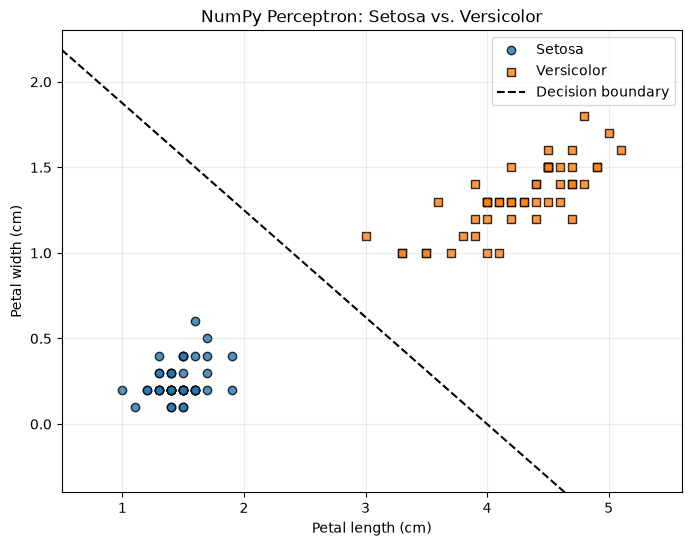

In [3]:
# Plot the training points and the learned decision boundary.
plt.figure(figsize=(8, 6))
for class_id, class_name, marker in [(0, "Setosa", "o"), (1, "Versicolor", "s")]:
    class_mask = y_iris == class_id
    plt.scatter(
        X_iris[class_mask, 0], X_iris[class_mask, 1],
        label=class_name, marker=marker, edgecolor="black", alpha=0.8
    )

x_min, x_max = X_iris[:, 0].min() - 0.5, X_iris[:, 0].max() + 0.5
y_min, y_max = X_iris[:, 1].min() - 0.5, X_iris[:, 1].max() + 0.5

if abs(weights[1]) > 1e-12:
    x_values = np.linspace(x_min, x_max, 300)
    y_values = -(weights[0] * x_values + bias) / weights[1]
    plt.plot(x_values, y_values, "k--", label="Decision boundary")
else:
    # A vertical boundary is possible if the learned second weight is zero.
    x_boundary = -bias / weights[0]
    plt.axvline(x_boundary, color="black", linestyle="--", label="Decision boundary")

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("NumPy Perceptron: Setosa vs. Versicolor")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Q2. Load Fashion-MNIST and display a 3×3 sample grid

100%|██████████| 26.4M/26.4M [00:05<00:00, 4.61MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 184kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 2.11MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


Training images: 60,000
Test images: 10,000
Training batches (batch_size=64): 938
Test batches (batch_size=64): 157


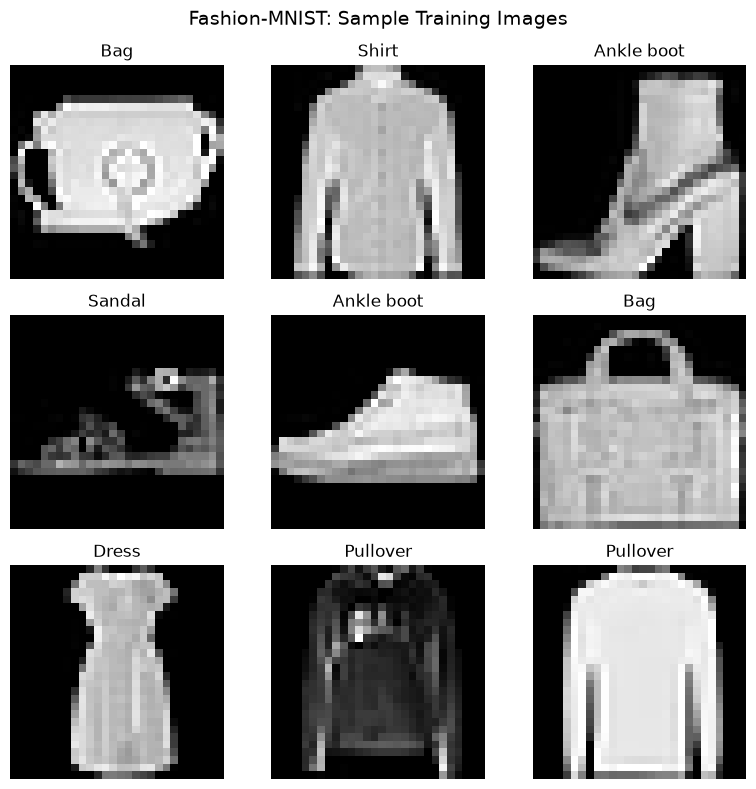

In [4]:
# Fashion-MNIST class names in the dataset's label order.
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Training images: {len(train_dataset):,}")
print(f"Test images: {len(test_dataset):,}")
print(f"Training batches (batch_size=64): {len(train_loader):,}")
print(f"Test batches (batch_size=64): {len(test_loader):,}")

# Display nine reproducibly selected training images.
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(train_dataset), size=9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for ax, idx in zip(axes.flat, sample_indices):
    image_tensor, label = train_dataset[int(idx)]
    ax.imshow(image_tensor.squeeze(0), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")
fig.suptitle("Fashion-MNIST: Sample Training Images", fontsize=14)
plt.tight_layout()
plt.show()

## Q3. Build and train the Fashion-MNIST neural network

The requested architecture is used exactly:

`Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

The model is trained for 15 epochs with `CrossEntropyLoss` and Adam (`lr=0.001`). Accuracy is evaluated on the complete training and test splits after every epoch. The table highlights epochs 5, 10, and 15.

In [5]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def calculate_accuracy(model, data_loader, device):
    """Return accuracy in [0, 1] over every example in data_loader."""
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            predictions = logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return correct / total


epoch_losses = []
train_accuracies = []
test_accuracies = []
num_epochs = 15

for epoch in range(1, num_epochs + 1):
    model.train()
    running_loss = 0.0
    examples_seen = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        examples_seen += batch_size

    average_loss = running_loss / examples_seen
    train_acc = calculate_accuracy(model, train_loader, device)
    test_acc = calculate_accuracy(model, test_loader, device)

    epoch_losses.append(average_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch [{epoch:02d}/{num_epochs}] | "
        f"Loss: {average_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Test Acc: {test_acc * 100:.2f}%"
    )

# Required comparison table for epochs 5, 10, and 15.
selected_epochs = [5, 10, 15]
accuracy_table = pd.DataFrame({
    "Epoch": selected_epochs,
    "Train Accuracy (%)": [train_accuracies[e - 1] * 100 for e in selected_epochs],
    "Test Accuracy (%)": [test_accuracies[e - 1] * 100 for e in selected_epochs]
})
print("\nAccuracy at selected epochs:")
display(accuracy_table.round(2))

Epoch [01/15] | Loss: 0.5216 | Train Acc: 86.55% | Test Acc: 85.01%
Epoch [02/15] | Loss: 0.3713 | Train Acc: 87.11% | Test Acc: 85.56%
Epoch [03/15] | Loss: 0.3326 | Train Acc: 88.25% | Test Acc: 86.19%
Epoch [04/15] | Loss: 0.3076 | Train Acc: 89.60% | Test Acc: 87.34%
Epoch [05/15] | Loss: 0.2913 | Train Acc: 90.04% | Test Acc: 87.74%
Epoch [06/15] | Loss: 0.2751 | Train Acc: 89.87% | Test Acc: 87.16%
Epoch [07/15] | Loss: 0.2615 | Train Acc: 90.94% | Test Acc: 88.17%
Epoch [08/15] | Loss: 0.2490 | Train Acc: 91.45% | Test Acc: 88.34%
Epoch [09/15] | Loss: 0.2393 | Train Acc: 91.39% | Test Acc: 88.14%
Epoch [10/15] | Loss: 0.2310 | Train Acc: 91.36% | Test Acc: 87.96%
Epoch [11/15] | Loss: 0.2219 | Train Acc: 92.20% | Test Acc: 88.82%
Epoch [12/15] | Loss: 0.2124 | Train Acc: 92.27% | Test Acc: 88.70%
Epoch [13/15] | Loss: 0.2059 | Train Acc: 92.33% | Test Acc: 88.23%
Epoch [14/15] | Loss: 0.1983 | Train Acc: 93.47% | Test Acc: 89.04%
Epoch [15/15] | Loss: 0.1927 | Train Acc: 93.34%

,Epoch,Train Accuracy (%),Test Accuracy (%)
0,5,90.04,87.74
1,10,91.36,87.96
2,15,93.34,88.98


## Q4. Training loss and accuracy curves

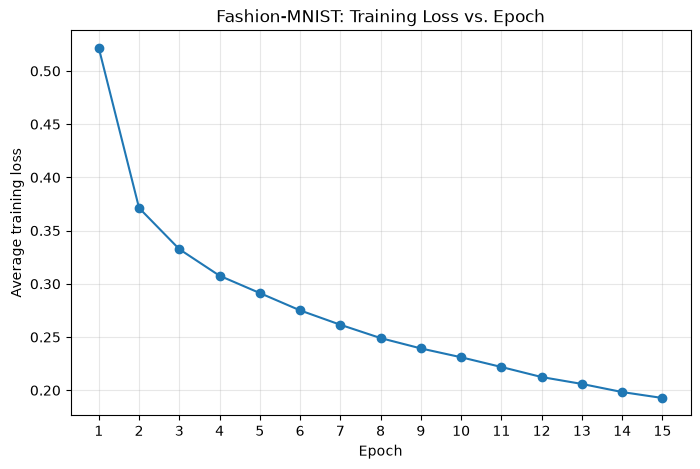

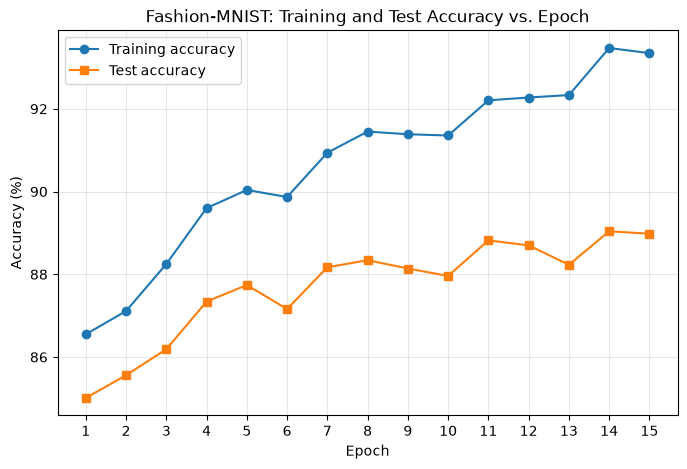

In [6]:
epochs_axis = range(1, num_epochs + 1)

# Figure 1: training loss vs. epoch.
plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, epoch_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Fashion-MNIST: Training Loss vs. Epoch")
plt.xticks(list(epochs_axis))
plt.grid(alpha=0.3)
plt.show()

# Figure 2: training and test accuracy vs. epoch.
plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, np.array(train_accuracies) * 100, marker="o", label="Training accuracy")
plt.plot(epochs_axis, np.array(test_accuracies) * 100, marker="s", label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Fashion-MNIST: Training and Test Accuracy vs. Epoch")
plt.xticks(list(epochs_axis))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Q5. Confusion matrix, overall accuracy, precision, and recall

Rows of the confusion matrix represent true labels and columns represent predicted labels. To identify the pair most often confused with each other, the notebook finds the two distinct classes with the largest combined off-diagonal counts `CM[i, j] + CM[j, i]`. It then reports precision and recall separately for both classes.

Overall test accuracy: 88.98%


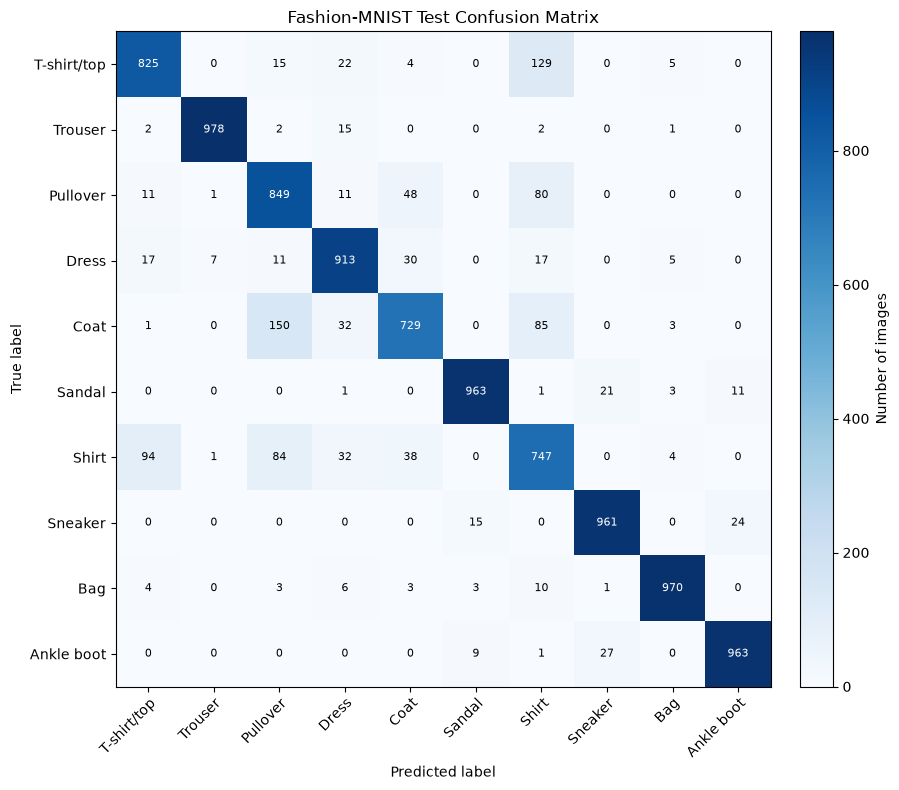

Most-confused pair: T-shirt/top and Shirt (combined errors: 223)

Precision and recall for the two most-confused classes:


,Class,Precision,Recall,True Positives
0,T-shirt/top,0.8648,0.825,825
1,Shirt,0.6968,0.747,747


In [7]:
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu().numpy()
        y_pred.extend(predictions.tolist())
        y_true.extend(labels.numpy().tolist())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))

overall_test_accuracy = np.trace(cm) / cm.sum()
print(f"Overall test accuracy: {overall_test_accuracy * 100:.2f}%")

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Number of images")
ax.set(
    xticks=np.arange(10), yticks=np.arange(10),
    xticklabels=class_names, yticklabels=class_names,
    xlabel="Predicted label", ylabel="True label",
    title="Fashion-MNIST Test Confusion Matrix"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
threshold = cm.max() / 2
for row in range(10):
    for col in range(10):
        ax.text(
            col, row, f"{cm[row, col]}",
            ha="center", va="center",
            color="white" if cm[row, col] > threshold else "black",
            fontsize=8
        )
fig.tight_layout()
plt.show()

# Find the most-confused unordered pair using bidirectional errors.
pair_error_counts = cm + cm.T
np.fill_diagonal(pair_error_counts, -1)
class_a, class_b = np.unravel_index(np.argmax(pair_error_counts), pair_error_counts.shape)

print(
    f"Most-confused pair: {class_names[class_a]} and {class_names[class_b]} "
    f"(combined errors: {cm[class_a, class_b] + cm[class_b, class_a]})"
)

rows = []
for class_id in [class_a, class_b]:
    tp = cm[class_id, class_id]
    predicted_as_class = cm[:, class_id].sum()
    actually_class = cm[class_id, :].sum()
    precision = tp / predicted_as_class if predicted_as_class else 0.0
    recall = tp / actually_class if actually_class else 0.0
    rows.append({
        "Class": class_names[class_id],
        "Precision": precision,
        "Recall": recall,
        "True Positives": int(tp)
    })

confused_class_metrics = pd.DataFrame(rows)
print("\nPrecision and recall for the two most-confused classes:")
display(confused_class_metrics.round(4))

## Q6. Show 16 test images with predicted and true labels

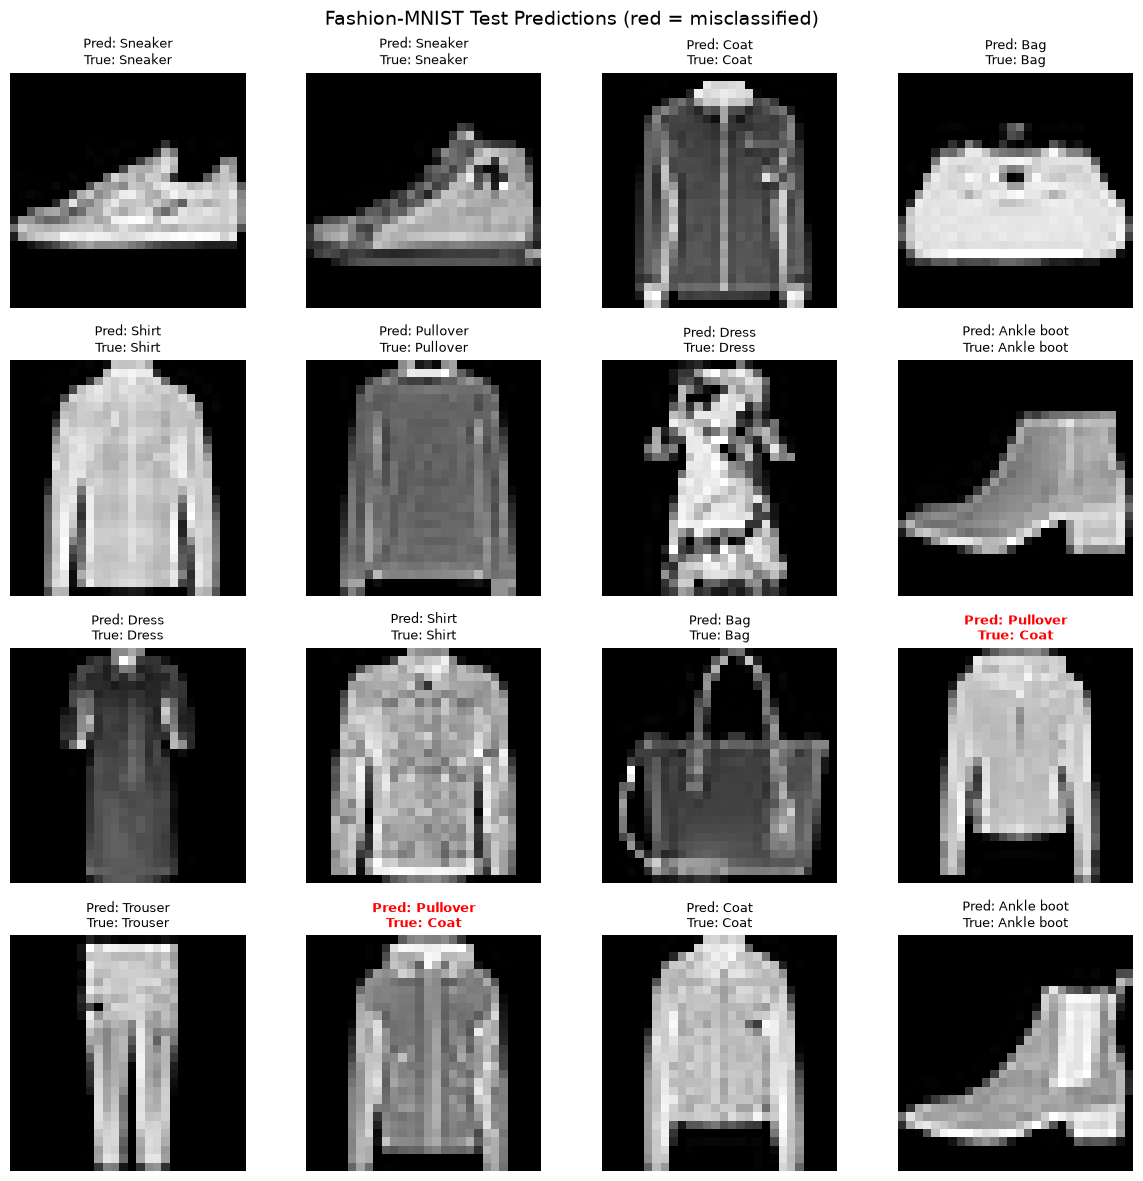

Misclassified images in this 4×4 sample: 2/16


In [8]:
# Reproducibly select 16 test images and get predictions.
rng = np.random.default_rng(SEED + 1)
test_indices = rng.choice(len(test_dataset), size=16, replace=False)
images_to_show = torch.stack([test_dataset[int(i)][0] for i in test_indices])
true_labels = np.array([test_dataset[int(i)][1] for i in test_indices])

model.eval()
with torch.no_grad():
    predicted_labels = model(images_to_show.to(device)).argmax(dim=1).cpu().numpy()

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, image_tensor, true_label, predicted_label in zip(
    axes.flat, images_to_show, true_labels, predicted_labels
):
    is_wrong = predicted_label != true_label
    ax.imshow(image_tensor.squeeze(0), cmap="gray")
    ax.set_title(
        f"Pred: {class_names[predicted_label]}\nTrue: {class_names[true_label]}",
        color="red" if is_wrong else "black",
        fontsize=9,
        fontweight="bold" if is_wrong else "normal"
    )
    ax.axis("off")

fig.suptitle("Fashion-MNIST Test Predictions (red = misclassified)", fontsize=14)
plt.tight_layout()
plt.show()

misclassified_in_grid = int(np.sum(predicted_labels != true_labels))
print(f"Misclassified images in this 4×4 sample: {misclassified_in_grid}/16")

## Q7 (Optional). California Housing regression with PyTorch

The eight input features are standardized using statistics fitted on the training split only. The target (median house value, in units of $100,000) is left on its original scale. The requested network is trained for 100 epochs using MSE loss and Adam (`lr=0.01`).

In [9]:
# Download/load the California Housing dataset.
housing = fetch_california_housing()
X_house = housing.data.astype(np.float32)
y_house = housing.target.astype(np.float32).reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=SEED
)

# Standardize features; fit only on the training split to avoid data leakage.
housing_scaler = StandardScaler()
X_train_scaled = housing_scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = housing_scaler.transform(X_test).astype(np.float32)

train_house_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled), torch.from_numpy(y_train)
)
test_house_dataset = TensorDataset(
    torch.from_numpy(X_test_scaled), torch.from_numpy(y_test)
)

house_train_loader = DataLoader(
    train_house_dataset, batch_size=256, shuffle=True
)
house_test_loader = DataLoader(
    test_house_dataset, batch_size=256, shuffle=False
)

print(f"Training rows: {len(train_house_dataset):,}")
print(f"Test rows: {len(test_house_dataset):,}")

Training rows: 16,512
Test rows: 4,128


In [10]:
housing_model = nn.Sequential(
    nn.Linear(8, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

housing_criterion = nn.MSELoss()
housing_optimizer = torch.optim.Adam(housing_model.parameters(), lr=0.01)
housing_epochs = 100
housing_train_losses = []

for epoch in range(1, housing_epochs + 1):
    housing_model.train()
    total_squared_error = 0.0
    total_rows = 0

    for features, targets in house_train_loader:
        features = features.to(device)
        targets = targets.to(device)

        housing_optimizer.zero_grad(set_to_none=True)
        predictions = housing_model(features)
        loss = housing_criterion(predictions, targets)
        loss.backward()
        housing_optimizer.step()

        batch_rows = targets.size(0)
        total_squared_error += loss.item() * batch_rows
        total_rows += batch_rows

    epoch_mse = total_squared_error / total_rows
    housing_train_losses.append(epoch_mse)

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch [{epoch:03d}/{housing_epochs}] | Training MSE: {epoch_mse:.4f}")

# Generate predictions for the complete held-out test split.
housing_model.eval()
all_house_predictions = []
all_house_actual = []
with torch.no_grad():
    for features, targets in house_test_loader:
        predictions = housing_model(features.to(device)).cpu().numpy()
        all_house_predictions.append(predictions)
        all_house_actual.append(targets.numpy())

all_house_predictions = np.vstack(all_house_predictions).ravel()
all_house_actual = np.vstack(all_house_actual).ravel()

rmse = float(np.sqrt(np.mean((all_house_actual - all_house_predictions) ** 2)))
mae = float(np.mean(np.abs(all_house_actual - all_house_predictions)))
print(f"\nCalifornia Housing test RMSE: {rmse:.4f}")
print(f"California Housing test MAE:  {mae:.4f}")
print("Metric unit: target units of $100,000.")

Epoch [001/100] | Training MSE: 1.2855
Epoch [010/100] | Training MSE: 0.3258
Epoch [020/100] | Training MSE: 0.2928
Epoch [030/100] | Training MSE: 0.2779
Epoch [040/100] | Training MSE: 0.2638
Epoch [050/100] | Training MSE: 0.2575
Epoch [060/100] | Training MSE: 0.2622
Epoch [070/100] | Training MSE: 0.2498
Epoch [080/100] | Training MSE: 0.2446
Epoch [090/100] | Training MSE: 0.2475
Epoch [100/100] | Training MSE: 0.2377

California Housing test RMSE: 0.5203
California Housing test MAE:  0.3466
Metric unit: target units of $100,000.


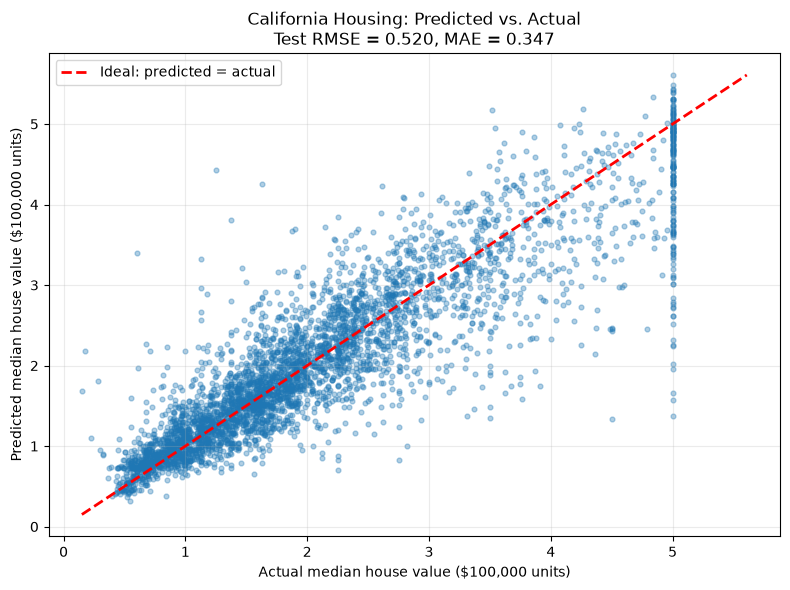

In [11]:
# Predicted vs. actual target values with a y = x reference line.
plot_min = min(all_house_actual.min(), all_house_predictions.min())
plot_max = max(all_house_actual.max(), all_house_predictions.max())

plt.figure(figsize=(8, 6))
plt.scatter(all_house_actual, all_house_predictions, alpha=0.35, s=12)
plt.plot([plot_min, plot_max], [plot_min, plot_max], "r--", linewidth=2, label="Ideal: predicted = actual")
plt.xlabel("Actual median house value ($100,000 units)")
plt.ylabel("Predicted median house value ($100,000 units)")
plt.title(f"California Housing: Predicted vs. Actual\nTest RMSE = {rmse:.3f}, MAE = {mae:.3f}")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## End of notebook

### Submission checklist
- **Q1:** Final NumPy perceptron weights/bias printed; decision boundary plotted.
- **Q2:** Both Fashion-MNIST splits loaded with `ToTensor()` and batch-size-64 DataLoaders; 3×3 image grid displayed.
- **Q3:** Requested network trained for 15 epochs; train/test accuracy table shown for epochs 5, 10, and 15.
- **Q4:** Separate training-loss and train/test-accuracy figures generated.
- **Q5:** 10×10 confusion matrix plotted; overall accuracy and precision/recall for the most-confused pair printed.
- **Q6:** 4×4 prediction grid generated; incorrect predictions have red titles.
- **Q7 (optional):** California Housing model trained for 100 epochs; test RMSE, MAE, and predicted-vs-actual plot generated.

For a clean submission, run **Kernel → Restart Kernel and Run All**, then save the notebook with the outputs included.